Part a

In [1]:
import pandas as pd
#The directories
file_path_data = 'F:/Aidin/Universities/Amirkabir (Master)/Lessons/Term 2/Pattern Recognition/Assignments/HW1/Answer/Cellphones Recommendations/cellphones data.csv'
file_path_ratings = 'F:/Aidin/Universities/Amirkabir (Master)/Lessons/Term 2/Pattern Recognition/Assignments/HW1/Answer/Cellphones Recommendations/cellphones ratings.csv'
file_path_users = 'F:/Aidin/Universities/Amirkabir (Master)/Lessons/Term 2/Pattern Recognition/Assignments/HW1/Answer/Cellphones Recommendations/cellphones users.csv'

try:
    #Loading all data frames from directories
    df_data = pd.read_csv(file_path_data)
    df_ratings = pd.read_csv(file_path_ratings)
    df_users = pd.read_csv(file_path_users)
    
    #Displaying the head (first 5th sample of dataframes)
    print("Cellphones Data:")
    print(df_data.head(), '\n')
    print("Cellphones Ratings:")
    print(df_ratings.head(), '\n')
    print("Cellphones Users:")
    print(df_users.head(), '\n')
    
except Exception as e:
    #Displaying error when an error in loading happened
    print("An error occurred for loading:", e)

Cellphones Data:
   cellphone_id  brand              model operating system  internal memory  \
0             0  Apple   iPhone SE (2022)              iOS              128   
1             1  Apple     iPhone 13 Mini              iOS              128   
2             2  Apple          iPhone 13              iOS              128   
3             3  Apple      iPhone 13 Pro              iOS              256   
4             4  Apple  iPhone 13 Pro Max              iOS              256   

   RAM  performance  main camera  selfie camera  battery size  screen size  \
0    4         7.23           12              7          2018          4.7   
1    4         7.72           12             12          2438          5.4   
2    4         7.75           12             12          3240          6.1   
3    6         7.94           12             12          3065          6.1   
4    6         8.01           12             12          4352          6.7   

   weight  price release date  
0     1

Part b

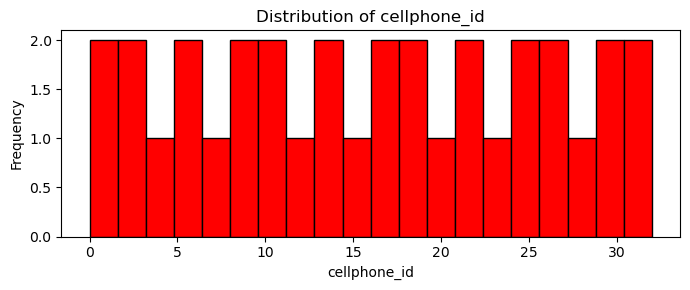

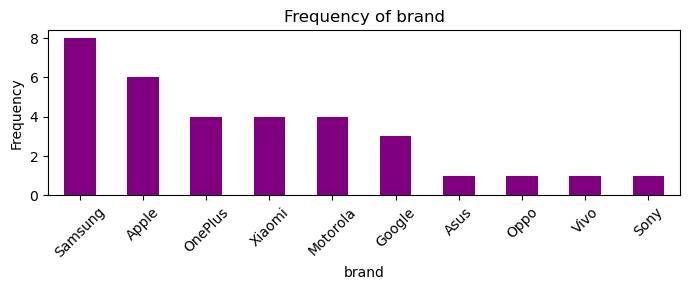

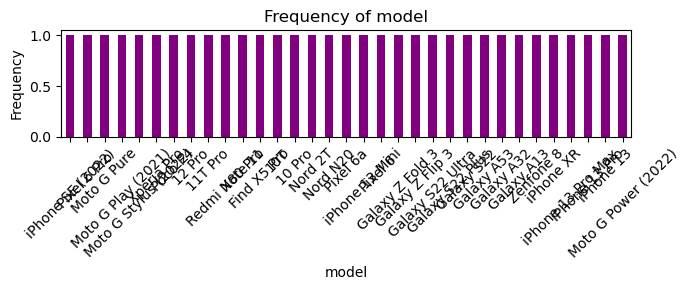

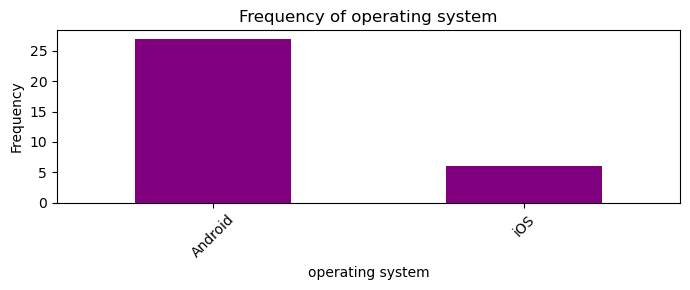

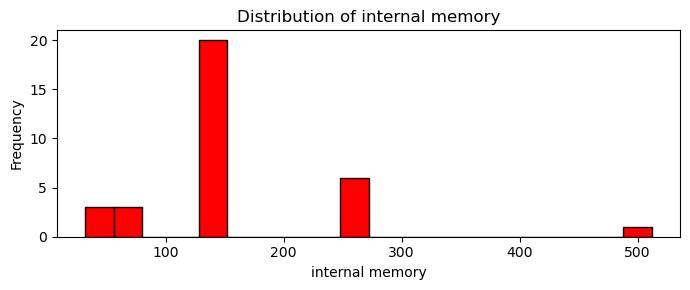

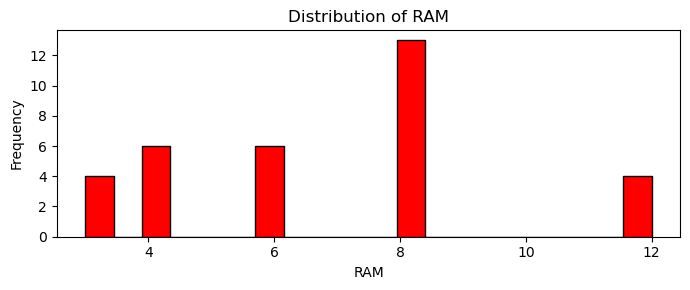

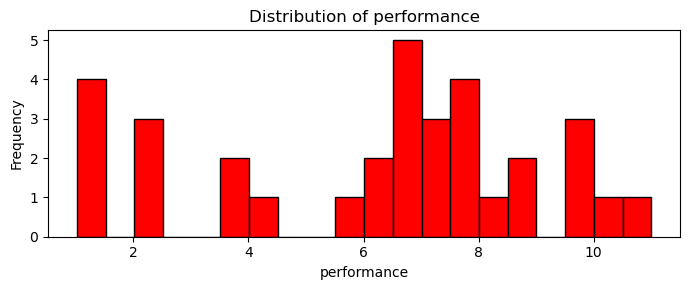

[Some figures were removed to keep the repository small; see report.pdf]


In [2]:
import matplotlib.pyplot as plt

for column in df_data.columns:
    # Checking and Seperating what to done for categorical or numerical data
    if df_data[column].dtype == 'object':  # For Categorical data like Brand and Model
        plt.figure(figsize=(7, 3))
        df_data[column].value_counts().plot(kind='bar', color='purple')
        plt.title(f'Frequency of {column}')
        plt.xlabel(f'{column}')
        plt.ylabel('Frequency')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

    elif pd.api.types.is_numeric_dtype(df_data[column]):  # For Numerical data like Price and Battery Size
        plt.figure(figsize=(7, 3))
        df_data[column].plot(kind='hist', bins=20, color='red', edgecolor='black')
        plt.title(f'Distribution of {column}')
        plt.xlabel(f'{column}')
        plt.ylabel('Frequency')
        plt.tight_layout()
        plt.show()

Part c

In [3]:
votes_per_phone = df_ratings.groupby('cellphone_id').size().reset_index(name='NumVotes')

# Merging this information into df_data (main data frame)
df_data_with_votes = pd.merge(df_data, votes_per_phone, on='cellphone_id', how='left')

# To make it compltete, we add this in order to if there is some samples with no votes, we replace NaN with 0
df_data_with_votes['NumVotes'].fillna(0, inplace=True)

print(df_data_with_votes.head())

   cellphone_id  brand              model operating system  internal memory  \
0             0  Apple   iPhone SE (2022)              iOS              128   
1             1  Apple     iPhone 13 Mini              iOS              128   
2             2  Apple          iPhone 13              iOS              128   
3             3  Apple      iPhone 13 Pro              iOS              256   
4             4  Apple  iPhone 13 Pro Max              iOS              256   

   RAM  performance  main camera  selfie camera  battery size  screen size  \
0    4         7.23           12              7          2018          4.7   
1    4         7.72           12             12          2438          5.4   
2    4         7.75           12             12          3240          6.1   
3    6         7.94           12             12          3065          6.1   
4    6         8.01           12             12          4352          6.7   

   weight  price release date  NumVotes  
0     144    4

Part d

In [4]:
import numpy as np
from scipy.stats import pearsonr, spearmanr
from sklearn.feature_selection import mutual_info_regression, mutual_info_classif
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor

# Dividing numerical and categorical featuresS
numerical_features = df_data_with_votes.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = df_data_with_votes.select_dtypes(exclude=[np.number]).columns.tolist()

# Remove NumVotes feature from the feature lists (it is the target)
numerical_features.remove('NumVotes')

# Calculating Pearson (linear relationship) and Spearman correlations (monotonic relationship, can capture non-linear dependencies) for numerical features and NumVotes
print("Dependency between numerical features and number of votes:")
for feature in numerical_features:
    pearson_corr, _ = pearsonr(df_data_with_votes[feature], df_data_with_votes['NumVotes'])
    spearman_corr, _ = spearmanr(df_data_with_votes[feature], df_data_with_votes['NumVotes'])
    print(f"{feature}: Pearson correlation = {pearson_corr:.4f}, Spearman correlation = {spearman_corr:.4f}")

# Calculating mutual information (captures non-linear relationships) for numerical features with NumVotes 
print("\nMutual information for numerical features with number of votes:")
mi_numeric = mutual_info_regression(df_data_with_votes[numerical_features], df_data_with_votes['NumVotes'])

for feature, mi in zip(numerical_features, mi_numeric):
    print(f"{feature}: Mutual information = {mi:.4f}")

# Calculating mutual information for categorical features with NumVotes
print("\nMutual information for categorical features with number of votes:")
mi_categorical = mutual_info_classif(pd.get_dummies(df_data_with_votes[categorical_features]), df_data_with_votes['NumVotes'])

for feature, mi in zip(categorical_features, mi_categorical):
    print(f"{feature}: Mutual information = {mi:.4f}")

# Polynomial regression for non-linear dependency
print("\nPolynomial regression for numerical features with number of votes:")
poly = PolynomialFeatures(degree=2)
for feature in numerical_features:
    X_poly = poly.fit_transform(df_data_with_votes[[feature]])
    poly_coeffs = np.polyfit(df_data_with_votes[feature], df_data_with_votes['NumVotes'], 2)
    print(f"{feature}: Polynomial regression coefficients = {poly_coeffs}")

# Using decision tree to measure non-linear dependency (feature importance)
print("\nDecision Tree Feature Importance:")
X_numeric = df_data_with_votes[numerical_features]
y_votes = df_data_with_votes['NumVotes']

# Fiting a decision tree regressor
tree = DecisionTreeRegressor(random_state=42)
tree.fit(X_numeric, y_votes)

# Feature importance scores
importances = tree.feature_importances_
for feature, importance in zip(numerical_features, importances):
    print(f"{feature}: Feature importance = {importance:.4f}")


C:\Program Files\Anaconda\lib\site-packages\scipy\__init__.py:155: UserWarning: A NumPy version >=1.18.5 and <1.25.0 is required for this version of SciPy (detected version 1.25.0
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


Dependency between numerical features and number of votes:
cellphone_id: Pearson correlation = 0.2637, Spearman correlation = 0.2586
internal memory: Pearson correlation = -0.2186, Spearman correlation = -0.2957
RAM: Pearson correlation = -0.1938, Spearman correlation = -0.2053
performance: Pearson correlation = -0.4305, Spearman correlation = -0.4177
main camera: Pearson correlation = 0.2079, Spearman correlation = 0.1867
selfie camera: Pearson correlation = -0.0701, Spearman correlation = -0.0281
battery size: Pearson correlation = 0.4106, Spearman correlation = 0.3430
screen size: Pearson correlation = 0.2414, Spearman correlation = -0.0088
weight: Pearson correlation = 0.1898, Spearman correlation = 0.1128
price: Pearson correlation = -0.3574, Spearman correlation = -0.4387

Mutual information for numerical features with number of votes:
cellphone_id: Mutual information = 0.0400
internal memory: Mutual information = 0.0000
RAM: Mutual information = 0.0000
performance: Mutual inform

Part e

In [5]:
# Calculating the total score for each phone
df_ratings['TotalScore'] = df_ratings['rating']
total_score_per_phone = df_ratings.groupby('cellphone_id')['TotalScore'].sum().reset_index(name='TotalScore')

df_data_with_scores = pd.merge(df_data, total_score_per_phone, on='cellphone_id', how='left')

numerical_features = ['internal memory', 'RAM', 'performance', 'main camera', 'selfie camera', 'battery size', 'screen size', 'weight', 'price']

#Calculating Pearson (linear relationship) and Spearman correlations (monotonic relationship, can capture non-linear dependencies) for numerical features and NumVotes
for feature in numerical_features:
    pearson_corr = df_data_with_scores[feature].corr(df_data_with_scores['TotalScore'], method='pearson')
    spearman_corr = df_data_with_scores[feature].corr(df_data_with_scores['TotalScore'], method='spearman')
    print(f"{feature}: Pearson correlation = {pearson_corr:.4f}, Spearman correlation = {spearman_corr:.4f}")

# Calculating mutual information (captures non-linear relationships) for numerical features with NumVotes 
# For numerical features
X_numerical = df_data_with_scores[numerical_features]
y_total_score = df_data_with_scores['TotalScore']
mi_numerical = mutual_info_regression(X_numerical, y_total_score)

print("\nMutual information for numerical features with total score:")
for feature, mi in zip(numerical_features, mi_numerical):
    print(f"{feature}: Mutual information = {mi:.4f}")

# For categorical features
categorical_features = ['brand', 'model', 'operating system', 'release date']
X_categorical = df_data_with_scores[categorical_features].apply(lambda col: col.astype('category').cat.codes)  # Encoding categorical features
mi_categorical = mutual_info_regression(X_categorical, y_total_score)

print("\nMutual information for categorical features with total score:")
for feature, mi in zip(categorical_features, mi_categorical):
    print(f"{feature}: Mutual information = {mi:.4f}")

# Polynomial regression for non-linear dependency
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Fit polynomial regression (degree 2) for each feature
print("\nPolynomial regression for numerical features with total score:")
for feature in numerical_features:
    X_poly = PolynomialFeatures(degree=2).fit_transform(df_data_with_scores[[feature]])
    poly_model = LinearRegression().fit(X_poly, df_data_with_scores['TotalScore'])
    print(f"{feature}: Polynomial regression coefficients = {poly_model.coef_}")

# Step 5: Decision Tree Regressor to find feature importance
from sklearn.tree import DecisionTreeRegressor

# Fiting a decision tree regressor
X = df_data_with_scores[numerical_features + categorical_features].apply(lambda col: col.astype('category').cat.codes if col.dtype == 'object' else col)
y = df_data_with_scores['TotalScore']

tree_model = DecisionTreeRegressor(random_state=42)
tree_model.fit(X, y)

# Extract feature importance
print("\nDecision Tree Feature Importance:")
for feature, importance in zip(numerical_features + categorical_features, tree_model.feature_importances_):
    print(f"{feature}: Feature importance = {importance:.4f}")


internal memory: Pearson correlation = 0.0454, Spearman correlation = 0.0159
RAM: Pearson correlation = -0.0789, Spearman correlation = -0.0770
performance: Pearson correlation = -0.0539, Spearman correlation = 0.0339
main camera: Pearson correlation = 0.2618, Spearman correlation = 0.0907
selfie camera: Pearson correlation = 0.1599, Spearman correlation = 0.2063
battery size: Pearson correlation = 0.2290, Spearman correlation = 0.3236
screen size: Pearson correlation = 0.0999, Spearman correlation = -0.0004
weight: Pearson correlation = 0.2008, Spearman correlation = 0.2790
price: Pearson correlation = -0.1500, Spearman correlation = -0.0799

Mutual information for numerical features with total score:
internal memory: Mutual information = 0.0000
RAM: Mutual information = 0.0000
performance: Mutual information = 0.0000
main camera: Mutual information = 0.0000
selfie camera: Mutual information = 0.0499
battery size: Mutual information = 0.1296
screen size: Mutual information = 0.0000
we

Part f

In [6]:
from sklearn.preprocessing import KBinsDiscretizer, PolynomialFeatures
from sklearn.metrics import mutual_info_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from scipy.stats import pearsonr, spearmanr

# Merging the ratings with the users to get age information
ratings_with_ages = pd.merge(df_ratings, df_users[['user_id', 'age']], on='user_id')

# Merging this with the cellphones data to get the full dataset with phone features and user ages
ratings_ages_features = pd.merge(ratings_with_ages, df_data, on='cellphone_id')

# Extracting the relevant columns that we want
age_and_features = ratings_ages_features[['age', 'internal memory', 'RAM', 'performance', 'main camera', 
                                          'selfie camera', 'battery size', 'screen size', 'weight', 'price']]

# Defining th function to compute Pearson and Spearman correlations (make it functional instead of writing every time)
def compute_correlations(feature_name):
    pearson_corr, _ = pearsonr(age_and_features['age'], age_and_features[feature_name])
    spearman_corr, _ = spearmanr(age_and_features['age'], age_and_features[feature_name])
    return pearson_corr, spearman_corr

# Computing correlations (Pearson and Spearman) for each feature
features = ['internal memory', 'RAM', 'performance', 'main camera', 'selfie camera', 'battery size', 'screen size', 'weight', 'price']
correlation_results = {feature: compute_correlations(feature) for feature in features}

# calculating mutual information (function the same as Pearson and Spearman)
def compute_mutual_information(column):
    discrete_age = KBinsDiscretizer(n_bins=10, encode='ordinal', strategy='uniform')
    age_binned = discrete_age.fit_transform(age_and_features[['age']])
    return mutual_info_score(age_binned[:, 0], age_and_features[column])

mutual_info_results = {feature: compute_mutual_information(feature) for feature in features}

# computing polynomial regression to capture non-linear relationships (function)
def compute_polynomial_regression(feature_name):
    poly = PolynomialFeatures(degree=2)
    X_poly = poly.fit_transform(age_and_features[['age']])
    lin_reg = LinearRegression()
    lin_reg.fit(X_poly, age_and_features[feature_name])
    return lin_reg.coef_

polynomial_results = {feature: compute_polynomial_regression(feature) for feature in features}

# The decision tree to determine feature importance
X = age_and_features[['internal memory', 'RAM', 'performance', 'main camera', 'selfie camera', 'battery size', 
                      'screen size', 'weight', 'price']]
y = age_and_features['age']

# Training and fiting decision tree
tree_model = DecisionTreeRegressor()
tree_model.fit(X, y)

# Feature importance
decision_tree_importances = dict(zip(features, tree_model.feature_importances_))

# printing out the results
print("Correlation Results (Pearson, Spearman):")
for feature, corr in correlation_results.items():
    print(f"{feature}: Pearson = {corr[0]:.4f}, Spearman = {corr[1]:.4f}")

print("\nMutual Information Results:")
for feature, mi in mutual_info_results.items():
    print(f"{feature}: MI = {mi:.4f}")

print("\nPolynomial Regression Coefficients:")
for feature, coef in polynomial_results.items():
    print(f"{feature}: Coefficients = {coef}")

print("\nDecision Tree Feature Importances:")
for feature, importance in decision_tree_importances.items():
    print(f"{feature}: Importance = {importance:.4f}")

Correlation Results (Pearson, Spearman):
internal memory: Pearson = 0.0029, Spearman = 0.0044
RAM: Pearson = -0.0163, Spearman = -0.0103
performance: Pearson = -0.0108, Spearman = -0.0111
main camera: Pearson = 0.0176, Spearman = 0.0187
selfie camera: Pearson = -0.0095, Spearman = 0.0116
battery size: Pearson = 0.0072, Spearman = -0.0023
screen size: Pearson = -0.0158, Spearman = -0.0257
weight: Pearson = -0.0327, Spearman = -0.0159
price: Pearson = -0.0330, Spearman = -0.0205

Mutual Information Results:
internal memory: MI = 0.0175
RAM: MI = 0.0141
performance: MI = 0.1200
main camera: MI = 0.0210
selfie camera: MI = 0.0434
battery size: MI = 0.0684
screen size: MI = 0.0409
weight: MI = 0.1070
price: MI = 0.1149

Polynomial Regression Coefficients:
internal memory: Coefficients = [ 0.          0.56176672 -0.00663932]
RAM: Coefficients = [ 0.00000000e+00 -6.10817767e-03  1.97881071e-05]
performance: Coefficients = [ 0.         -0.04550095  0.000525  ]
main camera: Coefficients = [ 0. 

C:\Program Files\Anaconda\lib\site-packages\sklearn\metrics\cluster\_supervised.py:65: UserWarning: Clustering metrics expects discrete values but received multiclass values for label, and continuous values for target
  warnings.warn(msg, UserWarning)
C:\Program Files\Anaconda\lib\site-packages\sklearn\metrics\cluster\_supervised.py:65: UserWarning: Clustering metrics expects discrete values but received multiclass values for label, and continuous values for target
  warnings.warn(msg, UserWarning)


Part h

In [7]:
# Creating a User-Item matrix
user_item_matrix = df_ratings.pivot_table(index='user_id', columns='cellphone_id', values='rating', fill_value=0)

# Saving the Excel file
user_item_matrix.to_excel('user_item_matrix.xlsx', index=True)

Part i

In [8]:
# Creating a User-Item matrix (Not completely due to handling NaN values)
user_item_matrix = df_ratings.pivot_table(index='user_id', columns='cellphone_id', values='rating')

# Calculating the mean rating for each cellphone (column-wise mean)
mean_item_rating = user_item_matrix.mean()

# Fill NaN values with the mean rating of each cellphone
user_item_matrix_filled = user_item_matrix.apply(lambda x: x.fillna(mean_item_rating[x.name]))

# Saving the Excel file
user_item_matrix_filled.to_excel('user_item_matrix_filled_with_mean.xlsx', index=True)

In [9]:
from sklearn.impute import KNNImputer

# Initializing the KNNImputer (we can adjust the number of neighbors)
knn_imputer = KNNImputer(n_neighbors=5, weights="uniform")

# Applying KNN Imputation to the user-item matrix
user_item_matrix_filled_knn = pd.DataFrame(knn_imputer.fit_transform(user_item_matrix), 
                                           index=user_item_matrix.index, 
                                           columns=user_item_matrix.columns)
# Save to an Excel file
user_item_matrix_filled_knn.to_excel('user_item_matrix_filled_knn.xlsx', index=True)

Part j 

In [16]:
# Computing A^T * A and A * A^T
AT_A = np.dot(user_item_matrix_filled_knn.T, user_item_matrix_filled_knn)  # A^T * A
A_AT = np.dot(user_item_matrix_filled_knn, user_item_matrix_filled_knn.T)  # A * A^T

# Computing the eigenvalues and eigenvectors for A * A^T (for U) and A^T * A (for V)
eigenvalues_U, eigenvectors_U = np.linalg.eig(A_AT)
eigenvalues_V, eigenvectors_V = np.linalg.eig(AT_A)

# Sorting eigenvalues and corresponding eigenvectors in descending order
sorted_indices_U = np.argsort(eigenvalues_U)[::-1]
U = eigenvectors_U[:, sorted_indices_U]  # U is the eigenvectors of A * A^T

sorted_indices_V = np.argsort(eigenvalues_V)[::-1]
V = eigenvectors_V[:, sorted_indices_V]  # V is the eigenvectors of A^T * A

# Constructing the diagonal matrix Σ (with singular values)
singular_values = np.sqrt(eigenvalues_U[sorted_indices_U])

# Constructing Σ (Sigma matrix)
Sigma = np.zeros_like(user_item_matrix)
np.fill_diagonal(Sigma, singular_values)

U_matrix = U
Sigma_matrix = Sigma
V_transposed = V.T

# Saving matrices to Excel file
with pd.ExcelWriter('svd_decomposition.xlsx') as writer:
    pd.DataFrame(U_matrix).to_excel(writer, sheet_name='U_matrix', index=False)
    pd.DataFrame(Sigma_matrix).to_excel(writer, sheet_name='Sigma_matrix', index=False)
    pd.DataFrame(V_transposed).to_excel(writer, sheet_name='V_transposed_matrix', index=False)

C:\Users\TamirLand\AppData\Roaming\Python\Python39\site-packages\numpy\lib\index_tricks.py:916: ComplexWarning: Casting complex values to real discards the imaginary part
  a.flat[:end:step] = val
